# Concrete Compressive Strength Prediction - Training Script Development

In [1]:
from pathlib import Path

import joblib
import shap
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer

from pipeline_util import setup_features, setup_format

SEED = 13

In [2]:
print(f"numpy=={np.__version__}")
print(f"pandas=={pd.__version__}")
print(f"sklearn=={sklearn.__version__}")
print(f"xgboost=={xgb.__version__}")

numpy==2.5.4
pandas==3.1.1
sklearn==1.9.1
xgboost==3.4.1


## 1 - Preprocessing

In [3]:
DATA_PATH = Path().cwd() / "data"
datasets = list(DATA_PATH.glob("data_src*.csv", case_sensitive=True))
datasets

[PosixPath('/mnt/d/Users/Esperine/Workspace3/_projects/_dev/buhos/data/data_src1.csv'),
 PosixPath('/mnt/d/Users/Esperine/Workspace3/_projects/_dev/buhos/data/data_src2.csv')]

In [4]:
columns = [
    "sample_id", 
    "src", 
    "cement", 
    "blast_furnace_slag", 
    "fly_ash", 
    "silica_fume", 
    "coarse_aggregate", 
    "fine_aggregate", 
    "water", 
    "superplasticizer", 
    "age", 
    "compressive_strength"
]

columns_fe = [
    "log_age",
    "ratio_wb",
    "pct_scm_repl"
]


features = columns[2:-2] + columns_fe
features_input = columns[2:-1]
target = "compressive_strength"


def wrangle_data(datasets: list[Path]) -> pd.DataFrame:
    frames = []
    for idx, file in enumerate(datasets):
        # Skip row containing the units of each column
        df_chunk = pd.read_csv(file, skiprows=[1])

        # Create unique ID and tag source
        df_chunk["sample_id"] = f"s{idx + 1}_" + (df_chunk.index + 1).astype(str)
        df_chunk["src"] = f"src{idx + 1}"

        frames.append(df_chunk)

    # Merge dataframes, fill null with zeroes, reorganize columns
    df = pd.concat(frames, ignore_index=True)
    df["silica_fume"] = df["silica_fume"].fillna(0)
    df = df.reindex(columns=columns)

    return df

In [5]:
# =====================================================================================
# Exported as a separated script to ensure joblib would create the binary properly
# View `train_util.py`
# =====================================================================================
    
# def setup_format(X: pd.DataFrame | pd.Series | dict | list) -> pd.DataFrame:
#     """Ensure model pipeline can accept multiple format."""

#     # Wrap input to a list if a single dictionary or Series
#     if isinstance(X, (dict, pd.Series)):
#         X = [X]

#     # Handles the following:
#     # 1. An existing DataFrame (creates a copy)
#     # 2. A list of dictionaries (creates a multi-row DataFrame)
#     # 3. A list-wrapped dict/Series (creates a 1-row DataFrame)
#     X_out = pd.DataFrame(X, copy=True)
#     return X_out


# def setup_features(X: pd.DataFrame) -> pd.DataFrame:
#     """Handles feature engineering within the model pipeline."""

#     # Remove irrelevant columns
#     X_out = X.drop(columns=["sample_id", "src"], errors="ignore")

#     # Scale age column into logarithmic values
#     X_out["log_age"] = np.log1p(X_out["age"])
#     X_out = X_out.drop(columns="age")

#     # Derive relevant features
#     scm_mats = ["blast_furnace_slag", "fly_ash", "silica_fume"]
#     total_scm = X_out[scm_mats].sum(axis=1)
#     total_binder = X_out["cement"] + total_scm
#     ratio_wb = X_out["water"].div(total_binder)
#     pct_scm_repl = total_scm.div(total_binder)
    
#     # Clean inf and NaN safely before saving values
#     X_out["ratio_wb"] = np.where(np.isfinite(ratio_wb), ratio_wb, 0.0)
#     X_out["pct_scm_repl"] = np.where(np.isfinite(pct_scm_repl), pct_scm_repl, 0.0)

#     return X_out

In [6]:
df = wrangle_data(datasets=datasets)
print(df.shape)
df.head()

(1627, 12)


,sample_id,src,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age,compressive_strength
0,s1_1,src1,540.0,0.0,0.0,0.0,1040.0,676.0,162.0,2.5,28,79.99
1,s1_2,src1,540.0,0.0,0.0,0.0,1055.0,676.0,162.0,2.5,28,61.89
2,s1_3,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,270,40.27
3,s1_4,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,365,41.05
4,s1_5,src1,198.6,132.4,0.0,0.0,978.4,825.5,192.0,0.0,360,44.30


## 2 - Train-validation-test split

For the purpose of peer reviewing and reproducibility, train the final model using only the train and validation set.

In [7]:
features_X = df[features_input]
target_y = df[target]

In [8]:
features_X

,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age
0,540.0,0.0,0.0,0.0,1040.0,676.0,162.0,2.5,28
1,540.0,0.0,0.0,0.0,1055.0,676.0,162.0,2.5,28
2,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,270
3,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,365
4,198.6,132.4,0.0,0.0,978.4,825.5,192.0,0.0,360
...,...,...,...,...,...,...,...,...,...
1622,422.0,0.0,141.0,141.0,900.0,524.0,176.0,0.0,3
1623,422.0,0.0,141.0,141.0,900.0,524.0,176.0,0.0,7
1624,422.0,0.0,141.0,141.0,900.0,524.0,176.0,0.0,28
1625,422.0,0.0,141.0,141.0,900.0,524.0,176.0,0.0,56


In [9]:
target_y

0       79.99
1       61.89
2       40.27
3       41.05
4       44.30
        ...  
1622    36.00
1623    54.00
1624    67.50
1625    72.00
1626    73.00
Name: compressive_strength, Length: 1627, dtype: float64

In [10]:
features_X.dtypes

cement                float64
blast_furnace_slag    float64
fly_ash               float64
silica_fume           float64
coarse_aggregate      float64
fine_aggregate        float64
water                 float64
superplasticizer      float64
age                     int64
dtype: object

In [11]:
X_full_train, X_test, y_full_train, y_test = train_test_split(
    features_X,
    target_y,
    test_size=0.2, 
    random_state=SEED
)

X_full_train.shape, X_test.shape, y_full_train.shape, y_test.shape

((1301, 9), (326, 9), (1301,), (326,))

Chosen model is XGBoost with the following parameters:
- `n_estimators` = 300
- `learning_rate` = 0.3
- `max_depth` = 4
- `min_child_weight` = 2

In [12]:
model_pipeline = Pipeline(steps=[
    ("setup_format", FunctionTransformer(setup_format, validate=False)),
    ("setup_features", FunctionTransformer(setup_features, validate=False)),
    ("model", xgb.XGBRegressor(
        n_estimators=300, 
        max_depth=4, 
        min_child_weight=2, 
        learning_rate=0.3, 
        random_state=SEED
    ))
])

model_pipeline.fit(X_full_train, y_full_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('setup_format', ...), ('setup_features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['cement','blast_furnace_slag','fly_ash',...,'water','superplasticizer', 'age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function set...x75484cb3aae0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [13]:
model_pipeline.named_steps

{'setup_format': FunctionTransformer(func=<function setup_format at 0x75484cb3aae0>),
 'setup_features': FunctionTransformer(func=<function setup_features at 0x75484cb3ab90>),
 'model': XGBRegressor(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.3, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=2, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, ...)}

In [14]:
model_pipeline.named_steps["setup_features"]

,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function set...x75484cb3ab90>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None
,"inv_kw_args inv_kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to inverse_func... versionadded:: 0.18",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` has featurenames that are all strings... versionadded:: 1.0","ndarray[object](9,)","['cement','blast_furnace_slag','fly_ash',...,'water','superplasticizer', 'age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9


In [15]:
model_pipeline.named_steps["setup_features"].feature_names_in_

array(['cement', 'blast_furnace_slag', 'fly_ash', 'silica_fume',
       'coarse_aggregate', 'fine_aggregate', 'water', 'superplasticizer',
       'age'], dtype=object)

In [16]:
model_pipeline.named_steps["model"]

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [17]:
model_pipeline.named_steps["model"].feature_names_in_

array(['cement', 'blast_furnace_slag', 'fly_ash', 'silica_fume',
       'coarse_aggregate', 'fine_aggregate', 'water', 'superplasticizer',
       'log_age', 'ratio_wb', 'pct_scm_repl'], dtype='<U18')

## 3 - Test scores and plots for reference

In [18]:
def predict(model, features_X, target_y, set_type):
    y_pred = model.predict(features_X)

    mae = mean_absolute_error(target_y, y_pred)
    rmse = root_mean_squared_error(target_y, y_pred)
    mape = mean_absolute_percentage_error(target_y, y_pred)
    r2, r2_adj = get_r2_scores(target_y, y_pred, list(features_X.columns))
    
    print(f"===== Scores - {set_type.upper()} =====")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAPE: {mape:.4f}")
    print(f"R2: {r2:.4f}")
    print(f"R2 Adjusted: {r2_adj:.4f}")
    
    return y_pred

def get_r2_scores(y_true, y_pred, features):
    r2 = r2_score(y_true, y_pred)
    
    n_samples = len(y_true)
    n_features = len(features)
    adj_r2 = 1 - (1 - r2) * (n_samples - 1) / (n_samples - n_features - 1)

    return r2, adj_r2

In [19]:
y_pred_test = predict(
    model=model_pipeline, 
    features_X=X_test, 
    target_y=y_test,
    set_type="test"
)

===== Scores - TEST =====
MAE: 2.8282
RMSE: 4.2429
MAPE: 0.0894
R2: 0.9559
R2 Adjusted: 0.9547


In [20]:
IMAGE_PATH = Path().cwd() / "images"
IMAGE_PATH

PosixPath('/mnt/d/Users/Esperine/Workspace3/_projects/_dev/buhos/images')

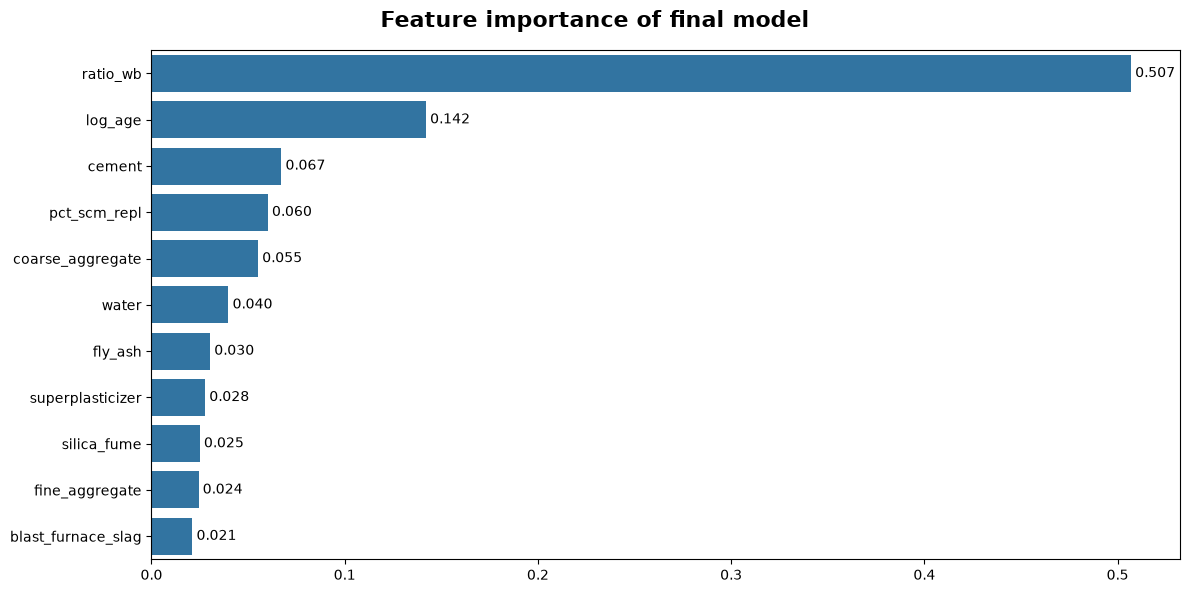

In [21]:
model_importances = pd.Series(
    data=model_pipeline[-1].feature_importances_,
    index=model_pipeline[-1].feature_names_in_
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=model_importances.sort_values(key=abs, ascending=False),
    orient="h",
    ax=ax
)

for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=3)

fig.suptitle("Feature importance of final model", fontsize=16, fontweight="bold")
fig.tight_layout()

plt.savefig(IMAGE_PATH / "feature_importance_final_model.jpg", dpi=300, bbox_inches="tight") 

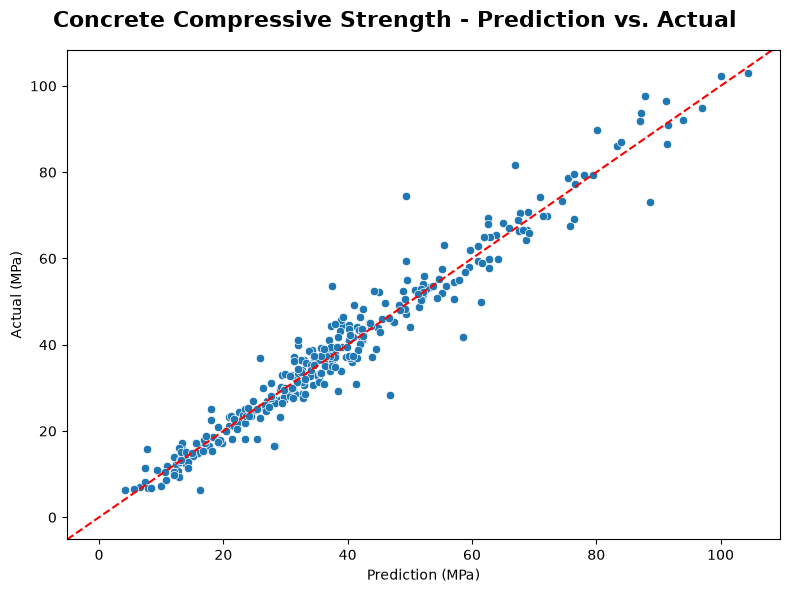

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(x=y_pred_test, y=y_test, ax=ax)
ax.axline((0, 0), slope=1, color="red", linestyle="--", linewidth=1.5)

ax.set_xlabel("Prediction (MPa)")
ax.set_ylabel("Actual (MPa)")
fig.suptitle("Concrete Compressive Strength - Prediction vs. Actual", fontsize=16, fontweight="bold")

fig.tight_layout()

plt.savefig(IMAGE_PATH / "plot_pred_vs_actual.jpg" , dpi=300, bbox_inches="tight")

Background dataset has 326 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=326 when initializing the masker.


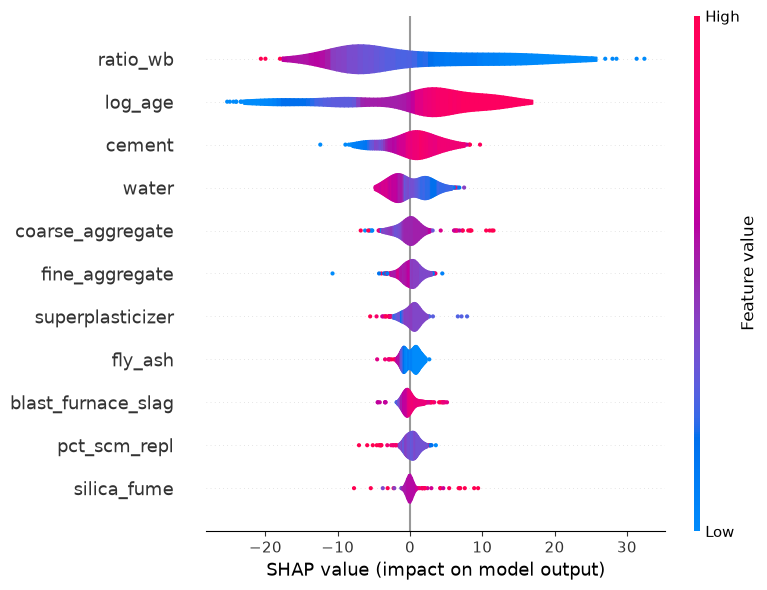

In [37]:
model = model_pipeline.named_steps["model"]
preprocessing_pipeline = model_pipeline[:-1] 
X_preprocessed = preprocessing_pipeline.transform(X_test)

explainer = shap.Explainer(model, X_preprocessed)
shap_values = explainer(X_preprocessed)
shap.summary_plot(shap_values, plot_type="violin", plot_size=(8, 6), show=False)

plt.tight_layout()

plt.savefig(IMAGE_PATH / "shap_summary_plot_final_model.png", dpi=300, bbox_inches="tight")

## 4 - Sample predictions

### 4.1 - Multiple inputs

In [24]:
# Select some samples that use a "normal" mix concrete (no SCMs, no superplasticizers) between 7 to 28 days of age

filter_1 = (df["blast_furnace_slag"] + df["fly_ash"] + df["silica_fume"]) == 0
filter_2 = df["superplasticizer"] == 0
filter_3 = df["age"] >= 7
filter_4 = df["age"] <= 28

sample_df = df[filter_1 & filter_2 & filter_3 & filter_4].iloc[:10]
sample_df

,sample_id,src,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age,compressive_strength
9,s1_10,src1,475.0,0.0,0.0,0.0,932.0,594.0,228.0,0.0,28,39.29
29,s1_30,src1,475.0,0.0,0.0,0.0,932.0,594.0,228.0,0.0,7,38.60
69,s1_70,src1,485.0,0.0,0.0,0.0,1120.0,800.0,146.0,0.0,28,71.99
375,s1_376,src1,376.0,0.0,0.0,0.0,1003.5,762.4,214.6,0.0,14,25.62
376,s1_377,src1,376.0,0.0,0.0,0.0,1003.5,762.4,214.6,0.0,28,31.97
394,s1_395,src1,405.0,0.0,0.0,0.0,1120.0,695.0,175.0,0.0,28,52.30
531,s1_532,src1,436.0,0.0,0.0,0.0,838.4,719.7,218.0,0.0,28,23.85
536,s1_537,src1,393.0,0.0,0.0,0.0,940.6,785.6,192.0,0.0,28,39.60
537,s1_538,src1,480.0,0.0,0.0,0.0,936.2,712.2,192.0,0.0,28,43.94
538,s1_539,src1,480.0,0.0,0.0,0.0,936.2,712.2,192.0,0.0,7,34.57


In [25]:
X_in = sample_df.drop(columns=target)
y_true = sample_df[target]

In [26]:
X_in_dict = X_in.to_dict(orient="records")
X_in_dict

[{'sample_id': 's1_10',
  'src': 'src1',
  'cement': 475.0,
  'blast_furnace_slag': 0.0,
  'fly_ash': 0.0,
  'silica_fume': 0.0,
  'coarse_aggregate': 932.0,
  'fine_aggregate': 594.0,
  'water': 228.0,
  'superplasticizer': 0.0,
  'age': 28},
 {'sample_id': 's1_30',
  'src': 'src1',
  'cement': 475.0,
  'blast_furnace_slag': 0.0,
  'fly_ash': 0.0,
  'silica_fume': 0.0,
  'coarse_aggregate': 932.0,
  'fine_aggregate': 594.0,
  'water': 228.0,
  'superplasticizer': 0.0,
  'age': 7},
 {'sample_id': 's1_70',
  'src': 'src1',
  'cement': 485.0,
  'blast_furnace_slag': 0.0,
  'fly_ash': 0.0,
  'silica_fume': 0.0,
  'coarse_aggregate': 1120.0,
  'fine_aggregate': 800.0,
  'water': 146.0,
  'superplasticizer': 0.0,
  'age': 28},
 {'sample_id': 's1_376',
  'src': 'src1',
  'cement': 376.0,
  'blast_furnace_slag': 0.0,
  'fly_ash': 0.0,
  'silica_fume': 0.0,
  'coarse_aggregate': 1003.5,
  'fine_aggregate': 762.4,
  'water': 214.6,
  'superplasticizer': 0.0,
  'age': 14},
 {'sample_id': 's1_377

In [27]:
# Test if model pipeline accepts a dataframe
model_pipeline.predict(X_in)

array([39.073586, 33.733166, 72.02895 , 26.143436, 33.265408, 50.148422,
       24.40543 , 40.017105, 45.1935  , 32.96838 ], dtype=float32)

In [28]:
# Test if model pipeline accepts a list of dictionaries
model_pipeline.predict(X_in_dict)

array([39.073586, 33.733166, 72.02895 , 26.143436, 33.265408, 50.148422,
       24.40543 , 40.017105, 45.1935  , 32.96838 ], dtype=float32)

### 4.2 - Single input

The following examples use actual mix designs using the ACI method.

In [29]:
# 24 MPa / ~3500 psi at 28 days (designed as 32.3 MPa accounting overdesign factor)

test_input = {
    "cement": 402,
    "blast_furnace_slag": 0,
    "fly_ash": 0,
    "silica_fume": 0,
    "coarse_aggregate": 992,
    "fine_aggregate": 732,
    "water": 205,
    "superplasticizer": 0,
    "age": 28
}

model_pipeline.predict(test_input)

array([34.895786], dtype=float32)

In [30]:
# 21 MPa / ~3000 psi at 28 days (no overdesign factor)

test_input = {
    "cement": 274.83,
    "blast_furnace_slag": 0,
    "fly_ash": 0,
    "silica_fume": 0,
    "coarse_aggregate": 934.21,
    "fine_aggregate": 944.44,
    "water": 177.77,
    "superplasticizer": 0,
    "age": 28
}

model_pipeline.predict(test_input)

array([25.876637], dtype=float32)

In [31]:
# 2000 psi / ~13.8 MPa at 28 days (no overdesign factor)
# This sample is an actual test done in a laboratory during my time as a student
# Highest actual strength measured during testing of cylinders is 13.8527 MPa

test_input = {
    "cement": 227.9,
    "blast_furnace_slag": 0,
    "fly_ash": 0,
    "silica_fume": 0,
    "coarse_aggregate": 1045.56,
    "fine_aggregate": 765.46,
    "water": 186.88,
    "superplasticizer": 0,
    "age": 28
}

model_pipeline.predict(test_input)

array([18.915707], dtype=float32)

## 5 - Exporting model

In [32]:
joblib.dump(model_pipeline, "csp_model.joblib")

['csp_model.joblib']

In [33]:
# IMPORTANT - pipeline_util.py must be located in the same directory as the model file before loading

csp_model = joblib.load("csp_model.joblib")
csp_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('setup_format', ...), ('setup_features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['cement','blast_furnace_slag','fly_ash',...,'water','superplasticizer', 'age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function set...x75484cb3aae0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [34]:
# Using a previous sample to test if import is working properly

test_input = {
    "cement": 402,
    "blast_furnace_slag": 0,
    "fly_ash": 0,
    "silica_fume": 0,
    "coarse_aggregate": 992,
    "fine_aggregate": 732,
    "water": 205,
    "superplasticizer": 0,
    "age": 28
}

csp_model.predict(test_input)

array([34.895786], dtype=float32)